# 🛡️ Sistem Deteksi Bullying dalam Chat
### Analisis Konten Chat Bahasa Indonesia dengan Machine Learning

---

**Tujuan:** Membangun sistem yang dapat secara otomatis mendeteksi apakah sebuah pesan chat mengandung indikasi perundungan (bullying) atau tidak.

**Pipeline:**
1. 📦 Load & eksplorasi dataset
2. 🔧 Preprocessing teks
3. 📊 Feature extraction (TF-IDF + Lexical)
4. 🤖 Training & evaluasi model
5. 🔍 Demo prediksi real-time
6. 📈 Visualisasi hasil

## ⚙️ Setup & Import

In [1]:
import sys
import os
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Tambahkan direktori proyek ke path
PROJECT_DIR = os.path.abspath('bullying_detection')
sys.path.insert(0, PROJECT_DIR)

print(f'Project dir: {PROJECT_DIR}')
print('✅ Setup selesai')

Project dir: C:\Users\LENOVO\OneDrive\Documents\web\bullying_detection
✅ Setup selesai


## 📦 1. Load Dataset

In [2]:
from data.dataset import get_dataframe, get_class_distribution

df = get_dataframe()
print(f'Jumlah data: {len(df)}')
get_class_distribution(df)
print()
df.head(10)

Jumlah data: 90
=== Distribusi Dataset ===
  Non-Bullying (0): 45 sampel
  Bullying     (1): 45 sampel
  Total            : 90 sampel



,text,label
0,"dasar jelek banget muka lo, kayak hantu",1
1,"lo tuh gendut banget sih, babi aja kalah",1
2,"item banget lo, jorok deh liat mukanya",1
3,kurus kering lo tuh makan dong jangan pelit,1
4,"pendek banget sih lo, kerdil emang",1
5,"bego banget sih lo, ga bisa apa-apa",1
6,"dasar idiot, soal gampang aja ga bisa",1
7,otak lo isi apa? kapas ya? makanya bodoh terus,1
8,lo tuh emang paling tolol di kelas,1
9,ngapain sekolah kalo otaknya mampet kayak gitu,1


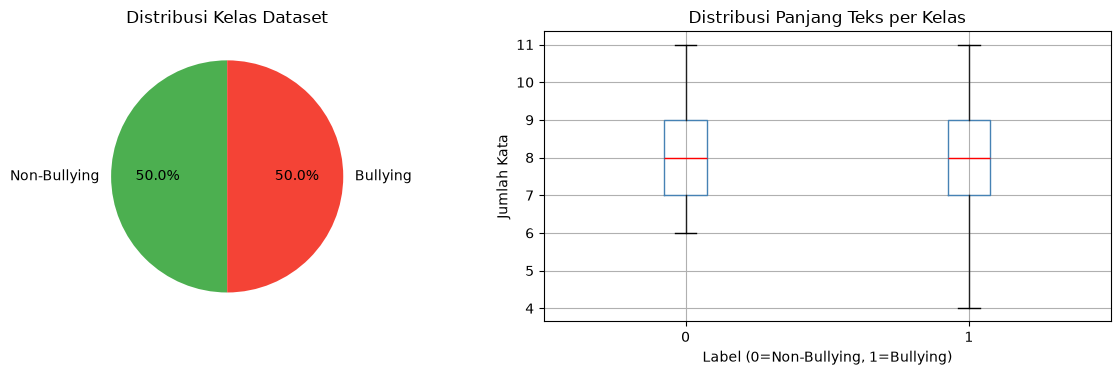


Rata-rata panjang teks:
label
0    8.111111
1    7.733333


In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Distribusi kelas
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pie chart
counts = df['label'].value_counts()
labels = ['Non-Bullying', 'Bullying']
colors = ['#4CAF50', '#F44336']
axes[0].pie(
    [counts.get(0, 0), counts.get(1, 0)],
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90
)
axes[0].set_title('Distribusi Kelas Dataset')

# Bar chart panjang teks
df['panjang_teks'] = df['text'].apply(lambda x: len(x.split()))
df.boxplot(
    column='panjang_teks',
    by='label',
    ax=axes[1],
    boxprops=dict(color='steelblue'),
    medianprops=dict(color='red')
)
axes[1].set_title('Distribusi Panjang Teks per Kelas')
axes[1].set_xlabel('Label (0=Non-Bullying, 1=Bullying)')
axes[1].set_ylabel('Jumlah Kata')
plt.suptitle('')
plt.tight_layout()
plt.show()
print(f"\nRata-rata panjang teks:")
print(df.groupby('label')['panjang_teks'].mean().to_string())

## 🔧 2. Preprocessing Teks

In [4]:
from preprocessing.text_preprocessor import preprocess, preprocess_batch

# Contoh preprocessing
contoh = [
    'dasar GOBLOK banget sih lo!! ga bisa apa-apa 😤',
    'hei, apa kabar? sudah lama ga ketemu nih :)',
    'awas lo ya!!! besok gw hajar lo abis-abisan!!!',
    'makasih udah bantuin aku tadi, baik banget deh',
]

print('=== Contoh Preprocessing ===')
print(f'{"Teks Original":<45} → {"Teks Preprocessed"}')
print('-' * 80)
for t in contoh:
    hasil = preprocess(t)
    print(f'{t[:44]:<45} → {hasil}')

=== Contoh Preprocessing ===
Teks Original                                 → Teks Preprocessed
--------------------------------------------------------------------------------
dasar GOBLOK banget sih lo!! ga bisa apa-apa  → dasar bodoh lo apaapa
hei, apa kabar? sudah lama ga ketemu nih :)   → hei kabar lama ketemu
awas lo ya!!! besok gw hajar lo abis-abisan!  → awas besok hajar abisabisan
makasih udah bantuin aku tadi, baik banget d  → terima kasih bantuin tadi baik


In [5]:
# Preprocessing seluruh dataset
df['text_clean'] = preprocess_batch(df['text'].tolist())
print('✅ Preprocessing selesai untuk', len(df), 'data')
print()
df[['text', 'text_clean', 'label']].head(8)

✅ Preprocessing selesai untuk 90 data



,text,text_clean,label
0,"dasar jelek banget muka lo, kayak hantu",dasar jelek muka lo hantu,1
1,"lo tuh gendut banget sih, babi aja kalah",gendut babi kalah,1
2,"item banget lo, jorok deh liat mukanya",item lo jorok liat mukanya,1
3,kurus kering lo tuh makan dong jangan pelit,kurus kering makan pelit,1
4,"pendek banget sih lo, kerdil emang",pendek lo kerdil memang,1
5,"bego banget sih lo, ga bisa apa-apa",bodoh lo apaapa,1
6,"dasar idiot, soal gampang aja ga bisa",dasar idiot soal gampang,1
7,otak lo isi apa? kapas ya? makanya bodoh terus,otak isi kapas makanya bodoh,1


## 📊 3. Feature Extraction

In [6]:
from features.feature_extractor import BullyingFeatureExtractor, LexicalFeatureExtractor

# Inisialisasi extractor
extractor = BullyingFeatureExtractor(
    tfidf_max_features=3000,
    tfidf_ngram_range=(1, 2)
)

texts_clean = df['text_clean'].tolist()
labels = np.array(df['label'].tolist())

# Ekstraksi fitur
X = extractor.fit_transform(texts_clean)

print('=== Informasi Fitur ===')
print(f'Shape matriks fitur : {X.shape}')
print(f'Fitur TF-IDF        : {len(extractor.tfidf.vocabulary_)}')
print(f'Fitur Leksikal      : {len(extractor.lexical.feature_names_)}')
print(f'Total Fitur         : {X.shape[1]}')

=== Informasi Fitur ===
Shape matriks fitur : (90, 577)
Fitur TF-IDF        : 566
Fitur Leksikal      : 11
Total Fitur         : 577


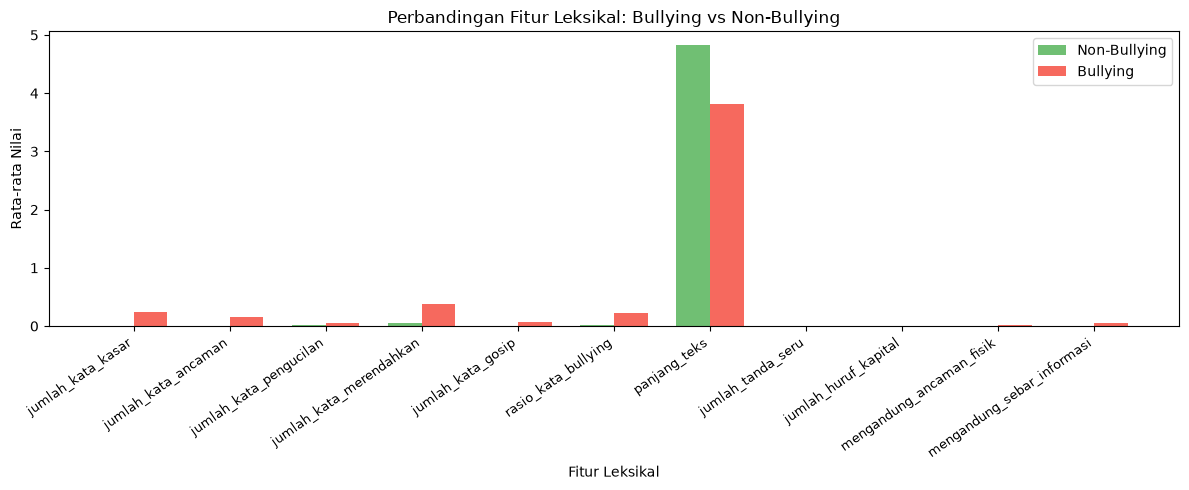

In [7]:
# Visualisasi fitur leksikal
lex_extractor = LexicalFeatureExtractor()
lex_features = lex_extractor.extract_batch(texts_clean)
lex_df = pd.DataFrame(lex_features, columns=lex_extractor.get_feature_names())
lex_df['label'] = labels

# Rata-rata fitur per kelas
mean_per_class = lex_df.groupby('label').mean()
mean_per_class.index = ['Non-Bullying', 'Bullying']

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(lex_extractor.get_feature_names()))
width = 0.35

ax.bar(x - width/2, mean_per_class.loc['Non-Bullying'], width,
       label='Non-Bullying', color='#4CAF50', alpha=0.8)
ax.bar(x + width/2, mean_per_class.loc['Bullying'], width,
       label='Bullying', color='#F44336', alpha=0.8)

ax.set_xlabel('Fitur Leksikal')
ax.set_ylabel('Rata-rata Nilai')
ax.set_title('Perbandingan Fitur Leksikal: Bullying vs Non-Bullying')
ax.set_xticks(x)
ax.set_xticklabels(lex_extractor.get_feature_names(), rotation=35, ha='right', fontsize=9)
ax.legend()
plt.tight_layout()
plt.show()

## 🤖 4. Training & Evaluasi Model

In [8]:
from models.trainer import BullyingModelTrainer

trainer = BullyingModelTrainer(test_size=0.2, random_state=42)
trainer.split_data(X, labels)
trainer.scale_features(fit=True)

# Latih semua model
trainer.train_all()

# Evaluasi
trainer.evaluate_all()
trainer.print_results()

Split data: 72 train | 18 test
  Train — Bullying: 36 | Non-Bullying: 36
  Test  — Bullying: 9 | Non-Bullying: 9

=== Training Semua Model ===
  Melatih Complement Naive Bayes (cocok untuk teks)... ✓
  Melatih Logistic Regression... ✓
  Melatih Support Vector Machine (LinearSVC + Calibration)... ✓
  Melatih Random Forest... ✓
  4 model berhasil dilatih.

=== Evaluasi Semua Model ===


HASIL EVALUASI MODEL

──────────────────────────────────────────────────
Model : Complement Naive Bayes (cocok untuk teks)
──────────────────────────────────────────────────
  Accuracy  : 0.7222
  Precision : 0.6429
  Recall    : 1.0000
  F1-Score  : 0.7826
  AUC-ROC   : 0.9136

  Classification Report:
              precision    recall  f1-score   support

Non-Bullying       1.00      0.44      0.62         9
    Bullying       0.64      1.00      0.78         9

    accuracy                           0.72        18
   macro avg       0.82      0.72      0.70        18
weighted avg       0.82      0.72  

In [9]:
# Pilih model terbaik
best_name, best_model = trainer.select_best_model(metric='f1_score')

# Tabel perbandingan
comparison = trainer.get_comparison_table()
comparison


Model terbaik (berdasarkan f1_score): logistic_regression
  f1_score: 0.8421


,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Complement Naive Bayes (cocok untuk teks),0.7222,0.6429,1.0000,0.7826,0.9136
1,Logistic Regression,0.8333,0.8000,0.8889,0.8421,0.9630
2,Support Vector Machine (LinearSVC + Calibration),0.8333,0.8750,0.7778,0.8235,0.9630
3,Random Forest,0.8333,0.8750,0.7778,0.8235,0.9630


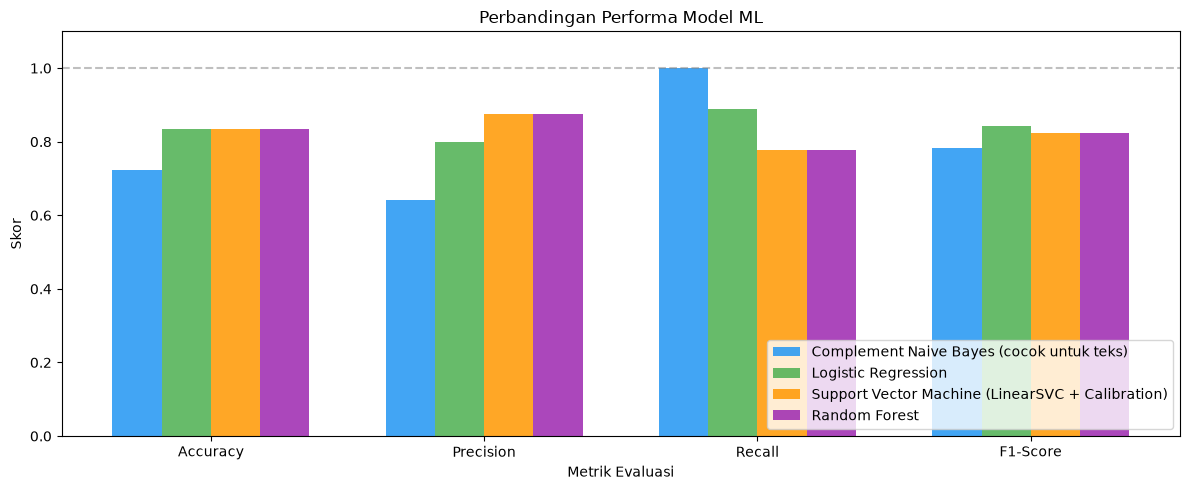

In [10]:
# Visualisasi perbandingan model
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
model_names = comparison['Model'].tolist()

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(metrics))
width = 0.18
colors_model = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']

for i, (name, color) in enumerate(zip(model_names, colors_model)):
    row = comparison[comparison['Model'] == name].iloc[0]
    values = [float(row[m]) for m in metrics]
    ax.bar(x + i * width - width * 1.5, values, width, label=name, color=color, alpha=0.85)

ax.set_xlabel('Metrik Evaluasi')
ax.set_ylabel('Skor')
ax.set_title('Perbandingan Performa Model ML')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)
ax.legend(loc='lower right')
ax.axhline(y=1.0, color='gray', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

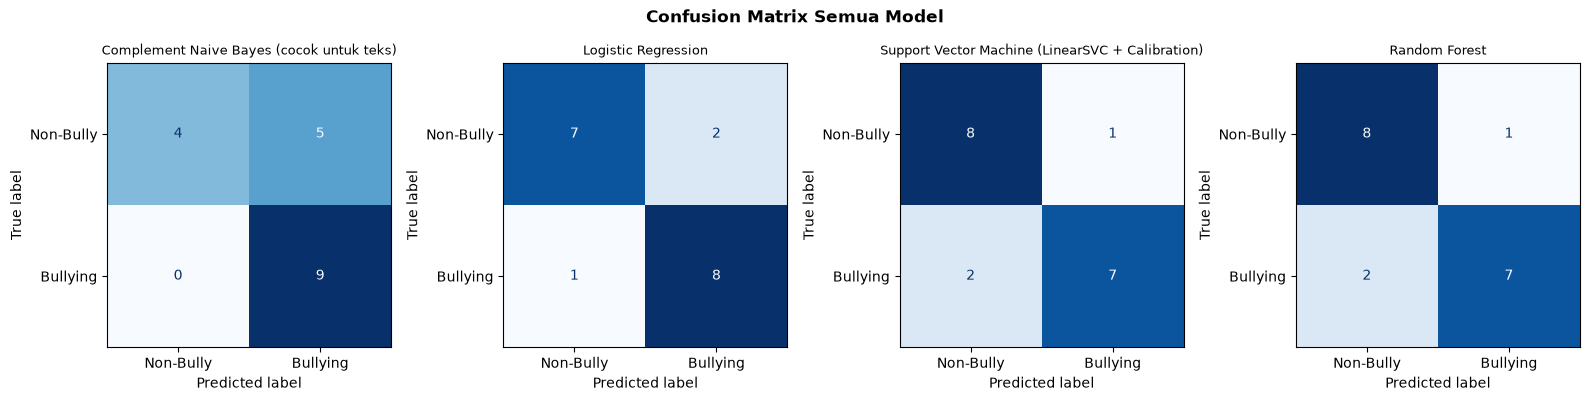

In [11]:
# Confusion matrix semua model
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
model_list = list(trainer.results.keys())

for idx, (name, ax) in enumerate(zip(model_list, axes)):
    cm = trainer.results[name]['confusion_matrix']
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Non-Bully', 'Bullying']
    )
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(trainer.results[name]['description'], fontsize=9)

plt.suptitle('Confusion Matrix Semua Model', fontweight='bold')
plt.tight_layout()
plt.show()

## 🔍 5. Demo Prediksi Real-Time

In [12]:
from inference.detector import BullyingDetector

# Inisialisasi & latih detector
detector = BullyingDetector()
result_train = detector.train(
    df=df[['text', 'label']],
    model_name='logistic_regression',
    save_dir='bullying_detection/saved_model'
)
print(f"F1-Score model: {result_train['f1_score']:.4f}")

[BullyingDetector] Melatih model: logistic_regression...
Split data: 72 train | 18 test
  Train — Bullying: 36 | Non-Bullying: 36
  Test  — Bullying: 9 | Non-Bullying: 9
  Melatih Logistic Regression... ✓
[BullyingDetector] Model disimpan ke: bullying_detection/saved_model
[BullyingDetector] Model siap digunakan.

F1-Score model: 0.8421


In [13]:
# Test prediksi individual
test_chats = [
    # Bullying
    'dasar goblok, ga bisa ngerjain soal gampang aja lo!',
    'awas lo ya, besok gue hajar abis-abisan!',
    'lo tuh sampah, semua orang benci sama lo',
    'gue udah screenshot chat lo, bakal gue sebar ke semua orang',
    'pergi aja sana, ga ada yang mau temenan sama lo',
    # Non-Bullying
    'semangat ya ujiannya, kamu pasti bisa!',
    'belajar bareng yuk besok sore, bareng teman-teman',
    'makasih bantuan lo tadi, sngt membantu banget',
    'ada PR apa aja buat besok? aku ketinggalan info',
    'cuaca hari ini enak banget buat olahraga ya',
]

print(f'{"-"*80}')
print(f'{"Teks Chat":<45} {"Status":<20} {"Risk":<12} {"P(Bully)"}')
print(f'{"-"*80}')

for chat in test_chats:
    r = detector.predict(chat)
    status_str = '⚠️ BULLYING' if r.label == 1 else '✅ AMAN'
    print(f'{chat[:44]:<45} {status_str:<20} {r.risk_level:<16} {r.confidence_bullying:.2%}')

print(f'{"-"*80}')

--------------------------------------------------------------------------------
Teks Chat                                     Status               Risk         P(Bully)
--------------------------------------------------------------------------------
dasar goblok, ga bisa ngerjain soal gampang   ⚠️ BULLYING          🔴 Tinggi         70.92%
awas lo ya, besok gue hajar abis-abisan!      ⚠️ BULLYING          🔴 Tinggi         80.29%
lo tuh sampah, semua orang benci sama lo      ⚠️ BULLYING          🔴 Tinggi         86.11%
gue udah screenshot chat lo, bakal gue sebar  ⚠️ BULLYING          🔴 Tinggi         88.31%
pergi aja sana, ga ada yang mau temenan sama  ⚠️ BULLYING          🔴 Tinggi         75.19%
semangat ya ujiannya, kamu pasti bisa!        ✅ AMAN               🟢 Rendah         36.37%
belajar bareng yuk besok sore, bareng teman-  ✅ AMAN               🟢 Rendah         14.95%
makasih bantuan lo tadi, sngt membantu bange  ✅ AMAN               🟢 Rendah         13.98%
ada PR apa aja buat b

In [14]:
# Analisis percakapan lengkap
conversation = [
    {'sender': 'Budi',  'text': 'hei siti, tugas kamu tadi bagus!'},
    {'sender': 'Raka',  'text': 'ah biasa aja kali, dasar penjilat'},
    {'sender': 'Siti',  'text': 'makasih Budi, aku usaha keras kok'},
    {'sender': 'Raka',  'text': 'goblok banget lo siti, nyontek juga ga bisa'},
    {'sender': 'Budi',  'text': 'itu ga bener Raka, jangan gitu dong'},
    {'sender': 'Raka',  'text': 'awas lo Siti, gue kasih tau semua orang tentang lo'},
    {'sender': 'Siti',  'text': 'tolong jangan gitu Raka'},
    {'sender': 'Guru',  'text': 'ada apa ini? semua harus saling menghormati ya'},
    {'sender': 'Andi',  'text': 'betul pak, kita harus damai'},
    {'sender': 'Raka',  'text': 'terserah, gue pergi dulu'},
]

analisis = detector.analyze_conversation(conversation)

print(f'\n=== ANALISIS PERCAKAPAN ===')
print(f'Status           : {analisis["status"]}')
print(f'Total pesan      : {analisis["total_pesan"]}')
print(f'Pesan bullying   : {analisis["total_bullying"]} ({analisis["bullying_ratio"]:.1%})')

print(f'\nStatistik per Pengirim:')
print(f'{"-"*55}')
print(f'{"Pengirim":<12} {"Total":<8} {"Bullying":<10} {"Avg Risk"}')
print(f'{"-"*55}')
for sender, stats in analisis['sender_stats'].items():
    print(f'{sender:<12} {stats["total_pesan"]:<8} {stats["pesan_bullying"]:<10} {stats["avg_risk_score"]:.2f}')

print(f'\n⚠️  Pesan Bermasalah:')
for msg in analisis['flagged_messages']:
    print(f'  [{msg["risk_level"]}] {msg["sender"]}: "{msg["text"][:55]}"')
    if msg['keywords']:
        print(f'    Kata kunci: {msg["keywords"]}')


=== ANALISIS PERCAKAPAN ===
Status           : ⚠️ PERLU TINDAKAN
Total pesan      : 10
Pesan bullying   : 5 (50.0%)

Statistik per Pengirim:
-------------------------------------------------------
Pengirim     Total    Bullying   Avg Risk
-------------------------------------------------------
Budi         2        0          0.28
Raka         4        3          0.65
Siti         2        1          0.33
Guru         1        1          0.72
Andi         1        0          0.46

⚠️  Pesan Bermasalah:
  [🔴 Tinggi] Raka: "goblok banget lo siti, nyontek juga ga bisa"
    Kata kunci: ['bodoh']
  [🔴 Tinggi] Raka: "awas lo Siti, gue kasih tau semua orang tentang lo"
    Kata kunci: ['awas']
  [🟡 Sedang] Siti: "tolong jangan gitu Raka"
  [🔴 Tinggi] Guru: "ada apa ini? semua harus saling menghormati ya"
  [🟡 Sedang] Raka: "terserah, gue pergi dulu"
    Kata kunci: ['pergi']


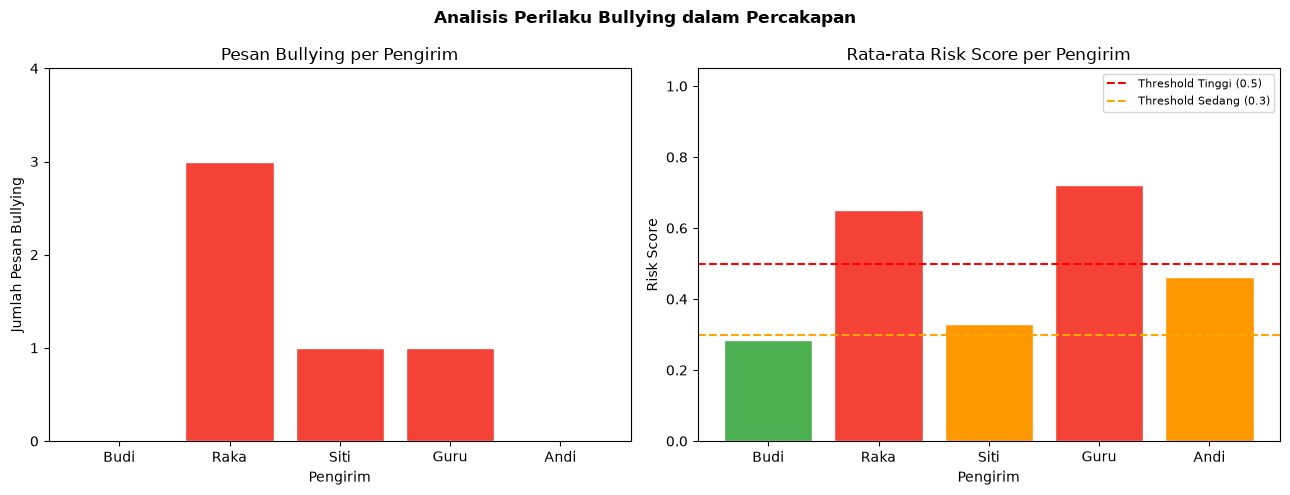

In [15]:
# Visualisasi analisis percakapan
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: Jumlah pesan bullying per pengirim
senders = list(analisis['sender_stats'].keys())
bully_counts = [analisis['sender_stats'][s]['pesan_bullying'] for s in senders]
bar_colors = ['#F44336' if c > 0 else '#4CAF50' for c in bully_counts]

axes[0].bar(senders, bully_counts, color=bar_colors, edgecolor='white')
axes[0].set_title('Pesan Bullying per Pengirim')
axes[0].set_xlabel('Pengirim')
axes[0].set_ylabel('Jumlah Pesan Bullying')
axes[0].set_yticks(range(max(bully_counts) + 2))

# Chart 2: Avg risk score per pengirim
risk_scores = [analisis['sender_stats'][s]['avg_risk_score'] for s in senders]
risk_colors = ['#F44336' if r >= 0.5 else ('#FF9800' if r >= 0.3 else '#4CAF50') for r in risk_scores]

axes[1].bar(senders, risk_scores, color=risk_colors, edgecolor='white')
axes[1].axhline(y=0.5, color='red', linestyle='--', label='Threshold Tinggi (0.5)')
axes[1].axhline(y=0.3, color='orange', linestyle='--', label='Threshold Sedang (0.3)')
axes[1].set_title('Rata-rata Risk Score per Pengirim')
axes[1].set_xlabel('Pengirim')
axes[1].set_ylabel('Risk Score')
axes[1].set_ylim(0, 1.05)
axes[1].legend(fontsize=8)

plt.suptitle('Analisis Perilaku Bullying dalam Percakapan', fontweight='bold')
plt.tight_layout()
plt.show()

## 💬 6. Coba Sendiri!

In [ ]:
# =====================================================
# 🎮 Masukkan teks chat Anda sendiri di bawah ini!
# =====================================================

TEKS_SAYA = "tulis pesan chat kamu di sini"

# =====================================================

r = detector.predict(TEKS_SAYA)

print('┌─────────────────────────────────────────────────┐')
print(f'│ Input    : {TEKS_SAYA[:46]:<46} │')
print(f'│ Proses   : {r.text_processed[:46]:<46} │')
print('├─────────────────────────────────────────────────┤')
status_icon = '⚠️  BULLYING' if r.label == 1 else '✅  TIDAK BULLYING'
print(f'│ Status   : {status_icon:<46} │')
print(f'│ Risk     : {r.risk_level:<46} │')
print(f'│ P(Bully) : {r.confidence_bullying:.2%}  |  P(Aman): {r.confidence_non_bullying:.2%}         │')
if r.detected_keywords:
    kw = ", ".join(r.detected_keywords)
    print(f'│ Keywords : {kw[:46]:<46} │')
if r.warning_message:
    print(f'│ ⚠️  {r.warning_message[:50]:<50} │')
print('└─────────────────────────────────────────────────┘')

---
## 📌 Kesimpulan

Sistem ini menggunakan kombinasi **TF-IDF** dan **Fitur Leksikal** untuk mendeteksi bullying.

| Komponen | Detail |
|---|---|
| **Dataset** | 90 sampel (45 bullying, 45 non-bullying) bahasa Indonesia |
| **Preprocessing** | Lowercase, hapus URL/emoji, normalisasi slang, stopwords |
| **Fitur** | TF-IDF bigram (3000 token) + 11 fitur leksikal |
| **Model** | Naive Bayes, Logistic Regression, SVM, Random Forest |
| **Output** | Label, probabilitas, risk level, kata kunci terdeteksi |

> 💡 **Untuk produksi:** Perbanyak dataset dengan data nyata, tambahkan annotasi manusia, dan gunakan model transformer (BERT/IndoBERT) untuk akurasi lebih tinggi.